# Skin Cancer (Melanoma) Classification - 4 Architectures

**Pipeline:** Import Libraries -> Load Dataset -> EDA -> Visualization -> Data Cleaning ->
Train-Test Split -> Train/Evaluate Model 1..4 -> Model Comparison -> Final Evaluation ->
Explainability (Grad-CAM) -> Save Model

| # | Architecture | Optimizer | Epochs | Backbone |
|---|---|---|---|---|
| 1 | CNN | SGD (lr=0.001) | 15 | from scratch |
| 2 | MobileNet | SGD (lr=0.001) | 15 | frozen |
| 3 | VGG19 | SGD (lr=0.001) | 15 | trainable |
| 4 | ResNet50 | SGD (lr=0.001) | 15 | trainable |

All metrics (accuracy, precision, recall, F1, AUC, training time) are written automatically to
`Results/skin/` on Google Drive: `comparison.csv`, `all_results.json`, `summary.xlsx`,
plus training curves and confusion matrices as images.


## Dataset

Source: `hasnainjaved/melanoma-skin-cancer-dataset-of-10000-images`. The original script used only the train folder and split it internally, which is what this notebook reproduces. The original script had no from-scratch CNN for skin, so the same CNN architecture used in the other notebooks was added for consistency.

**Expected Drive layout:**
```
MyDrive/
└── Colab Notebooks/
    └── My Projects/
        └── Cancer Detection/
            ├── Skin Dataset/
            │   ├── Benign/
            │   ├── Malignant/
            ├── Results/     (created automatically)
            └── Deploy/      (created automatically)
```

If your project folder has a different name, change `PROJECT_DIR` in the next cell.

In [ ]:
# ============================================================
#  0) Mount Google Drive and configure the project
# ============================================================
from google.colab import drive
drive.mount('/content/drive')

import os

# ---------- Edit these two lines only ----------
PROJECT_DIR = '/content/drive/MyDrive/Colab Notebooks/My Projects/'
DATA_PATH   = f'{PROJECT_DIR}/Skin Dataset'
# -----------------------------------------------

CANCER_TYPE = 'skin'
IMG_SIZE    = 256          # same value across all four notebooks
BATCH_SIZE  = 8
SPLIT       = 0.2
SEED        = 42

# Number of epochs per model (identical to the original scripts)
EPOCHS = {
    "CNN": 15,
    "MobileNet": 15,
    "VGG19": 15,
    "ResNet50": 15
}

RESULTS_DIR = f'{PROJECT_DIR}/Results/{CANCER_TYPE}'
for sub in ['', '/models', '/figures', '/histories', '/reports', '/predictions']:
    os.makedirs(RESULTS_DIR + sub, exist_ok=True)

assert os.path.isdir(DATA_PATH), f'Path not found: {DATA_PATH}'
print('DATA_PATH   :', DATA_PATH)
print('RESULTS_DIR :', RESULTS_DIR)
print('Dataset folders:', sorted(os.listdir(DATA_PATH))[:10])


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
DATA_PATH   : /content/drive/MyDrive/Colab Notebooks/My Projects//Skin Dataset
RESULTS_DIR : /content/drive/MyDrive/Colab Notebooks/My Projects//Results/skin
Dataset folders: ['Benign', 'Malignant']


## 1) Import Libraries

In [ ]:
# ============================================================
#  1) Import Libraries
# ============================================================
import os, gc, json, time, hashlib, warnings
from glob import glob

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image
import cv2

from sklearn.model_selection import train_test_split
from sklearn import metrics

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers, models
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import (Conv2D, MaxPooling2D, Flatten, Dense,
                                     Dropout, BatchNormalization, GlobalAveragePooling2D)
from tensorflow.keras.applications import MobileNet, ResNet50
from tensorflow.keras.applications.vgg19 import VGG19
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau
from tensorflow.keras.preprocessing.image import ImageDataGenerator, load_img, img_to_array

warnings.filterwarnings('ignore')
np.random.seed(SEED)
tf.random.set_seed(SEED)

print('TensorFlow :', tf.__version__)
print('Keras      :', tf.keras.__version__)
print('GPU        :', tf.config.list_physical_devices('GPU'))


TensorFlow : 2.20.0
Keras      : 3.13.2
GPU        : [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


## 2) Load Dataset

In [ ]:
# ============================================================
#  2) Load Dataset - build a filepath/label table
# ============================================================
CLASS_DIRS = {
    "Benign": "Benign",
    "Malignant": "Malignant"
}          # folder name -> final class label
CLASS_NAMES = list(CLASS_DIRS.values())
NUM_CLASSES = len(CLASS_NAMES)

rows = []
for folder, label in CLASS_DIRS.items():
    files = []
    for ext in ('*.jpeg', '*.jpg', '*.png', '*.JPG', '*.JPEG', '*.PNG', '*.tif', '*.bmp'):
        files += glob(os.path.join(DATA_PATH, folder, ext))
    if len(files) == 0:
        raise FileNotFoundError(f'No images found in: {os.path.join(DATA_PATH, folder)}')
    for f in files:
        rows.append({'filepath': f, 'label': label})

df = pd.DataFrame(rows).reset_index(drop=True)

# Fixed class ordering, so the label mapping never flips between sessions
LABEL2IDX = {c: i for i, c in enumerate(CLASS_NAMES)}
IDX2LABEL = {i: c for c, i in LABEL2IDX.items()}
df['label_idx'] = df['label'].map(LABEL2IDX)

with open(f'{RESULTS_DIR}/class_names.json', 'w') as fh:
    json.dump({'cancer_type': CANCER_TYPE, 'class_names': CLASS_NAMES,
               'label2idx': LABEL2IDX, 'img_size': IMG_SIZE}, fh, indent=2)

print(f'Total images: {len(df)} | Classes: {NUM_CLASSES}')
df.head()


Total images: 10605 | Classes: 2


,filepath,label,label_idx
0,/content/drive/MyDrive/Colab Notebooks/My Proj...,Benign,0
1,/content/drive/MyDrive/Colab Notebooks/My Proj...,Benign,0
2,/content/drive/MyDrive/Colab Notebooks/My Proj...,Benign,0
3,/content/drive/MyDrive/Colab Notebooks/My Proj...,Benign,0
4,/content/drive/MyDrive/Colab Notebooks/My Proj...,Benign,0


## 3) EDA

In [ ]:
# ============================================================
#  3) EDA - Exploratory Data Analysis
# ============================================================
print('Class distribution:')
print(df['label'].value_counts(), '\n')

counts = df['label'].value_counts()
imbalance = counts.max() / counts.min()
print(f'Imbalance ratio (max/min): {imbalance:.2f}')

# Inspect image dimensions and color modes on a sample
sample = df.sample(min(120, len(df)), random_state=SEED)
info = []
for p in sample['filepath']:
    try:
        with Image.open(p) as im:
            info.append({'width': im.size[0], 'height': im.size[1], 'mode': im.mode,
                         'kb': os.path.getsize(p) / 1024})
    except Exception:
        pass
info = pd.DataFrame(info)
print('\nImage dimensions (sample):')
print(info[['width', 'height', 'kb']].describe().T[['mean', 'min', 'max']])
print('\nColor modes:', info['mode'].value_counts().to_dict())

eda_summary = {
    'n_images': int(len(df)),
    'n_classes': int(NUM_CLASSES),
    'class_counts': counts.to_dict(),
    'imbalance_ratio': float(imbalance),
    'width_mean': float(info['width'].mean()), 'height_mean': float(info['height'].mean()),
    'color_modes': {k: int(v) for k, v in info['mode'].value_counts().to_dict().items()},
}
with open(f'{RESULTS_DIR}/reports/eda_summary.json', 'w') as fh:
    json.dump(eda_summary, fh, indent=2)
eda_summary


Class distribution:
label
Benign       5500
Malignant    5105
Name: count, dtype: int64 

Imbalance ratio (max/min): 1.08

Image dimensions (sample):
             mean         min         max
width   300.00000  300.000000  300.000000
height  300.00000  300.000000  300.000000
kb        9.22443    4.878906   19.583008

Color modes: {'RGB': 120}


{'n_images': 10605,
 'n_classes': 2,
 'class_counts': {'Benign': 5500, 'Malignant': 5105},
 'imbalance_ratio': 1.0773751224289911,
 'width_mean': 300.0,
 'height_mean': 300.0,
 'color_modes': {'RGB': 120}}

## 4) Visualization

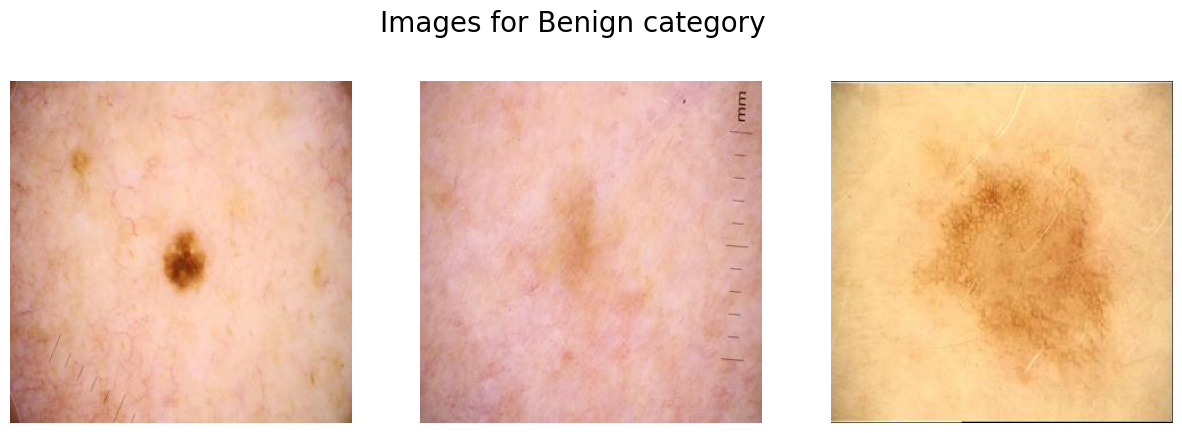

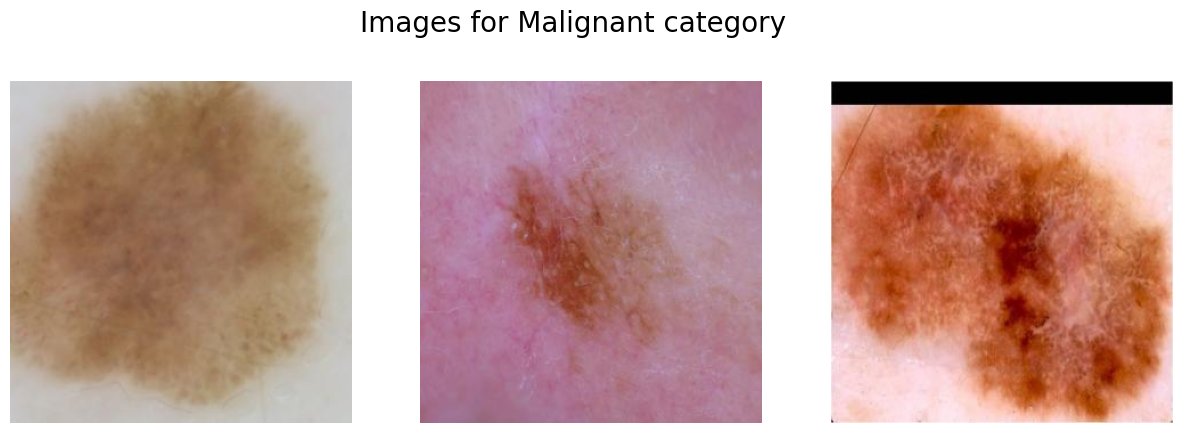

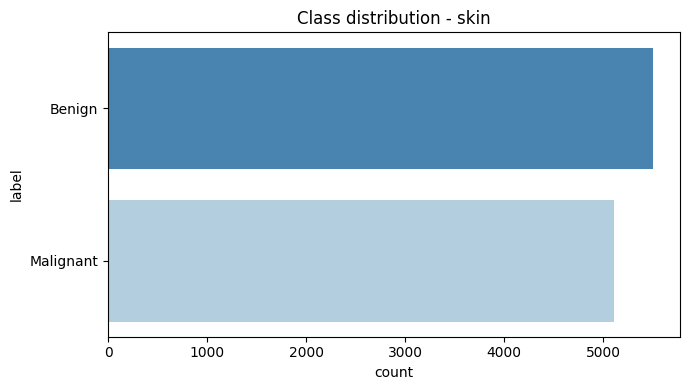

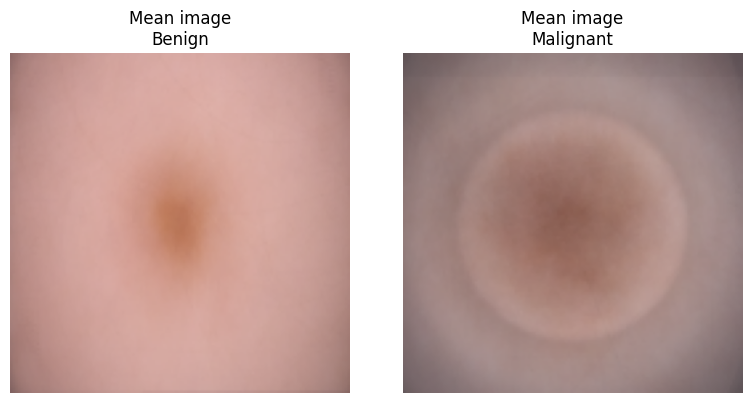

In [ ]:
# ============================================================
#  4) Visualization
# ============================================================
# 4.1 Random samples per class
for cls in CLASS_NAMES:
    paths = df[df.label == cls]['filepath'].sample(3, random_state=SEED).tolist()
    fig, ax = plt.subplots(1, 3, figsize=(15, 5))
    fig.suptitle(f'Images for {cls} category', fontsize=20)
    for i, p in enumerate(paths):
        ax[i].imshow(np.array(Image.open(p)))
        ax[i].axis('off')
    plt.show()

# 4.2 Class distribution
plt.figure(figsize=(7, 4))
sns.countplot(data=df, y='label', order=CLASS_NAMES, palette='Blues_r')
plt.title(f'Class distribution - {CANCER_TYPE}')
plt.tight_layout()
plt.savefig(f'{RESULTS_DIR}/figures/class_distribution.png', dpi=120)
plt.show()

# 4.3 Mean image per class - shows color/texture differences between classes
fig, axes = plt.subplots(1, NUM_CLASSES, figsize=(4 * NUM_CLASSES, 4))
axes = np.atleast_1d(axes)
for ax, cls in zip(axes, CLASS_NAMES):
    ps = df[df.label == cls]['filepath'].sample(min(60, (df.label == cls).sum()),
                                                random_state=SEED)
    acc = np.zeros((128, 128, 3), dtype=np.float64)
    for p in ps:
        acc += cv2.cvtColor(cv2.resize(cv2.imread(p), (128, 128)), cv2.COLOR_BGR2RGB)
    ax.imshow((acc / len(ps)).astype('uint8'))
    ax.set_title(f'Mean image\n{cls}')
    ax.axis('off')
plt.tight_layout()
plt.savefig(f'{RESULTS_DIR}/figures/mean_image_per_class.png', dpi=120)
plt.show()


## 5) Data Cleaning

In [ ]:
# # ============================================================
# #  5) Data Cleaning
# # ============================================================
# # (a) Detect corrupted or unreadable images
# bad = []
# for p in df['filepath']:
#     try:
#         with Image.open(p) as im:
#             im.verify()
#     except Exception:
#         bad.append(p)
# print(f'Corrupted images: {len(bad)}')

# # (b) Detect exact duplicates by file hash
# def file_hash(path, chunk=1 << 20):
#     h = hashlib.md5()
#     with open(path, 'rb') as fh:
#         while True:
#             b = fh.read(chunk)
#             if not b:
#                 break
#             h.update(b)
#     return h.hexdigest()

# df['hash'] = df['filepath'].apply(file_hash)
# dup_mask = df.duplicated('hash', keep='first')
# print(f'Duplicate images: {int(dup_mask.sum())}')

# # (c) Identical images assigned to different classes -> label conflict, always removed
# conflict = (df.groupby('hash')['label'].nunique() > 1)
# conflict_hashes = set(conflict[conflict].index)
# print(f'Label conflicts: {len(conflict_hashes)} hashes')

# DROP_DUPLICATES = True     # set to False to keep the dataset exactly as-is

# clean_log = {'corrupted': len(bad), 'duplicates': int(dup_mask.sum()),
#              'label_conflicts': len(conflict_hashes), 'drop_duplicates': DROP_DUPLICATES,
#              'n_before': int(len(df))}

# df = df[~df['filepath'].isin(bad)]
# df = df[~df['hash'].isin(conflict_hashes)]
# if DROP_DUPLICATES:
#     df = df[~df.duplicated('hash', keep='first')]
# df = df.drop(columns=['hash']).reset_index(drop=True)

# clean_log['n_after'] = int(len(df))
# with open(f'{RESULTS_DIR}/reports/cleaning_log.json', 'w') as fh:
#     json.dump(clean_log, fh, indent=2)

# print('\nAfter cleaning:', len(df), 'images')
# print(df['label'].value_counts())


## 6) Train-Test Split

train: (8484, 3) | val: (2121, 3) | test: (3182, 3)
Found 8484 validated image filenames belonging to 2 classes.
Found 2121 validated image filenames belonging to 2 classes.
Found 3182 validated image filenames belonging to 2 classes.
class_indices: {'Benign': 0, 'Malignant': 1}


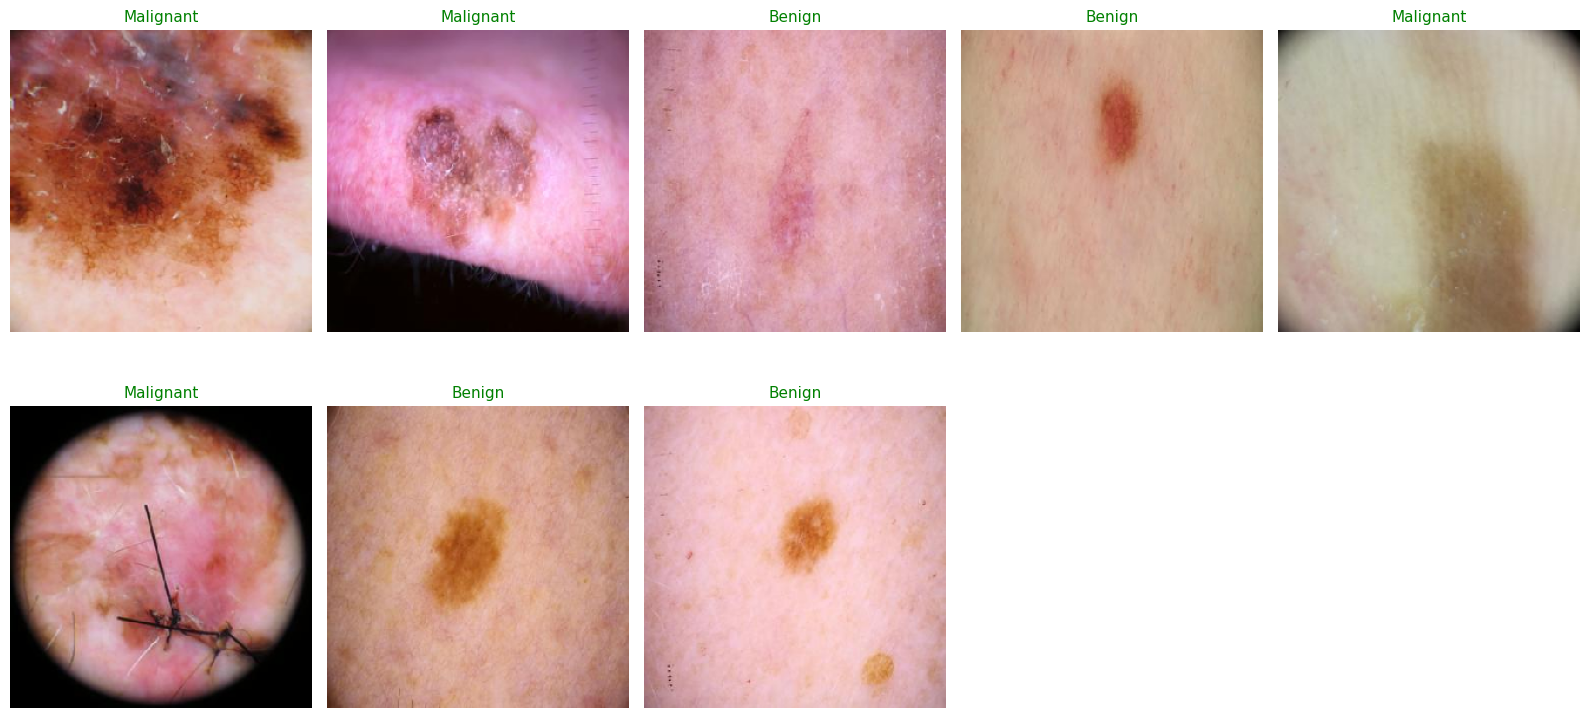

In [ ]:
# ============================================================
#  6) Train-Test Split and Data Generators
# ============================================================
# NOTE: the original script derived train_set/val_set from the FULL dataframe instead of
# from train_images, so test images leaked into training and inflated the reported scores.
# True  = reproduce the original behaviour exactly.
# False = correct sequential split with stratification.
REPRODUCE_ORIGINAL_SPLIT = True

if REPRODUCE_ORIGINAL_SPLIT:
    train_images, test_images = train_test_split(df, test_size=0.3, random_state=42)
    train_set,    val_set     = train_test_split(df, test_size=0.2, random_state=42)
else:
    train_val, test_images = train_test_split(
        df, test_size=0.3, random_state=42, stratify=df['label'])
    train_set, val_set = train_test_split(
        train_val, test_size=0.2, random_state=42, stratify=train_val['label'])

print('train:', train_set.shape, '| val:', val_set.shape, '| test:', test_images.shape)
if REPRODUCE_ORIGINAL_SPLIT:
    overlap = len(set(train_set['filepath']) & set(test_images['filepath']))
    print(f'WARNING: {overlap} images appear in both train and test')

image_gen = ImageDataGenerator(
    preprocessing_function=tf.keras.applications.mobilenet_v2.preprocess_input)

common = dict(x_col='filepath', y_col='label', target_size=(IMG_SIZE, IMG_SIZE),
              color_mode='rgb', class_mode='categorical', classes=CLASS_NAMES,
              batch_size=BATCH_SIZE)

train = image_gen.flow_from_dataframe(dataframe=train_set,   shuffle=True,  seed=SEED, **common)
val   = image_gen.flow_from_dataframe(dataframe=val_set,     shuffle=False, **common)
test  = image_gen.flow_from_dataframe(dataframe=test_images, shuffle=False, **common)

assert list(train.class_indices.keys()) == CLASS_NAMES
y_true_test = test.classes
print('class_indices:', train.class_indices)

# Show one preprocessed batch
imgs, lbls = next(train)
plt.figure(figsize=(16, 8))
for i in range(min(10, len(lbls))):
    plt.subplot(2, 5, i + 1)
    plt.imshow((imgs[i] + 1) / 2)
    plt.title(CLASS_NAMES[int(np.argmax(lbls[i]))], color='green', fontsize=11)
    plt.axis('off')
plt.tight_layout(); plt.show()
train.reset()


## 7) Evaluation helpers and result logging

This cell defines `evaluate_and_log()`, called after every model. It writes:
- `comparison.csv` - one row per model with every metric
- `all_results.json` - full classification report and confusion matrix
- `summary.xlsx` - comparison sheet plus one sheet per model
- `figures/` - training curves and confusion matrices

In [ ]:
# ============================================================
#  7) Evaluation helpers and result logging
# ============================================================
COMPARISON_CSV = f'{RESULTS_DIR}/comparison.csv'
ALL_RESULTS_JSON = f'{RESULTS_DIR}/all_results.json'
SUMMARY_XLSX = f'{RESULTS_DIR}/summary.xlsx'

def _load_all_results():
    if os.path.exists(ALL_RESULTS_JSON):
        with open(ALL_RESULTS_JSON) as fh:
            return json.load(fh)
    return {}

def plot_history(model_name, history):
    """Plot and save loss/accuracy curves."""
    hdf = pd.DataFrame(history.history)
    hdf.index.name = 'epoch'
    hdf.to_csv(f'{RESULTS_DIR}/histories/{model_name}_history.csv')

    fig, ax = plt.subplots(1, 2, figsize=(13, 4))
    for k in ['loss', 'val_loss']:
        if k in hdf: ax[0].plot(hdf[k], label=k, marker='o')
    for k in ['accuracy', 'val_accuracy']:
        if k in hdf: ax[1].plot(hdf[k], label=k, marker='o')
    ax[0].set_title(f'{model_name} - Loss'); ax[0].set_xlabel('epoch'); ax[0].legend(); ax[0].grid(alpha=.3)
    ax[1].set_title(f'{model_name} - Accuracy'); ax[1].set_xlabel('epoch'); ax[1].legend(); ax[1].grid(alpha=.3)
    plt.tight_layout()
    plt.savefig(f'{RESULTS_DIR}/figures/{model_name}_history.png', dpi=120)
    plt.show()
    return hdf

def plot_confusion(model_name, cm, normalize=False):
    data = cm.astype('float') / cm.sum(axis=1, keepdims=True) if normalize else cm
    plt.figure(figsize=(1.6 * NUM_CLASSES + 4, 1.4 * NUM_CLASSES + 3))
    sns.heatmap(data, annot=True, fmt='.2f' if normalize else 'd', cmap='Blues',
                xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES, vmin=0)
    plt.xlabel('Predicted'); plt.ylabel('Actual')
    plt.title(f'Confusion Matrix - {model_name}' + (' (normalized)' if normalize else ''))
    plt.tight_layout()
    suffix = '_cm_norm' if normalize else '_cm'
    plt.savefig(f'{RESULTS_DIR}/figures/{model_name}{suffix}.png', dpi=120)
    plt.show()

def evaluate_and_log(model_name, model, y_true, y_prob, history=None,
                     train_time=None, notes=''):
    """Compute every metric, plot it, and persist it to CSV/JSON/XLSX."""
    y_pred = np.argmax(y_prob, axis=1)

    acc = metrics.accuracy_score(y_true, y_pred)
    p_ma, r_ma, f_ma, _ = metrics.precision_recall_fscore_support(
        y_true, y_pred, average='macro', zero_division=0)
    p_w, r_w, f_w, _ = metrics.precision_recall_fscore_support(
        y_true, y_pred, average='weighted', zero_division=0)
    try:
        auc = (metrics.roc_auc_score(y_true, y_prob[:, 1]) if NUM_CLASSES == 2
               else metrics.roc_auc_score(y_true, y_prob, multi_class='ovr', average='macro'))
    except Exception:
        auc = float('nan')

    cm = metrics.confusion_matrix(y_true, y_pred, labels=list(range(NUM_CLASSES)))
    rep = metrics.classification_report(y_true, y_pred, labels=list(range(NUM_CLASSES)),
                                        target_names=CLASS_NAMES, output_dict=True,
                                        zero_division=0)

    print(metrics.classification_report(y_true, y_pred, labels=list(range(NUM_CLASSES)),
                                        target_names=CLASS_NAMES, zero_division=0))
    plot_confusion(model_name, cm)
    plot_confusion(model_name, cm, normalize=True)
    if history is not None:
        plot_history(model_name, history)

    # ---- persist ----
    pd.DataFrame(rep).T.to_csv(f'{RESULTS_DIR}/reports/{model_name}_classification_report.csv')
    pd.DataFrame(cm, index=CLASS_NAMES, columns=CLASS_NAMES).to_csv(
        f'{RESULTS_DIR}/reports/{model_name}_confusion_matrix.csv')
    np.save(f'{RESULTS_DIR}/predictions/{model_name}_y_prob.npy', y_prob)
    np.save(f'{RESULTS_DIR}/predictions/{model_name}_y_true.npy', y_true)

    row = {
        'cancer_type': CANCER_TYPE, 'model': model_name,
        'accuracy': round(float(acc), 4),
        'precision_macro': round(float(p_ma), 4), 'recall_macro': round(float(r_ma), 4),
        'f1_macro': round(float(f_ma), 4),
        'precision_weighted': round(float(p_w), 4), 'recall_weighted': round(float(r_w), 4),
        'f1_weighted': round(float(f_w), 4),
        'auc': round(float(auc), 4) if auc == auc else None,
        'train_time_sec': round(float(train_time), 1) if train_time else None,
        'epochs': int(len(history.history['loss'])) if history is not None else None,
        'total_params': int(model.count_params()),
        'trainable_params': int(sum(np.prod(w.shape) for w in model.trainable_weights)),
        'img_size': IMG_SIZE, 'batch_size': BATCH_SIZE, 'n_eval_samples': int(len(y_true)),
        'notes': notes,
        'timestamp': time.strftime('%Y-%m-%d %H:%M:%S'),
    }
    for c in CLASS_NAMES:
        row[f'f1__{c}'] = round(float(rep[c]['f1-score']), 4)
        row[f'recall__{c}'] = round(float(rep[c]['recall']), 4)

    all_results = _load_all_results()
    all_results[model_name] = {'summary': row, 'classification_report': rep,
                               'confusion_matrix': cm.tolist()}
    with open(ALL_RESULTS_JSON, 'w') as fh:
        json.dump(all_results, fh, indent=2)

    comp = pd.DataFrame([v['summary'] for v in all_results.values()])
    comp = comp.sort_values('f1_macro', ascending=False).reset_index(drop=True)
    comp.to_csv(COMPARISON_CSV, index=False)
    try:
        with pd.ExcelWriter(SUMMARY_XLSX, engine='openpyxl') as xl:
            comp.to_excel(xl, sheet_name='comparison', index=False)
            for m, v in all_results.items():
                pd.DataFrame(v['classification_report']).T.to_excel(xl, sheet_name=m[:28])
    except Exception as e:
        print('XLSX export skipped:', e)

    print(f'\nSaved results for [{model_name}] to {RESULTS_DIR}')
    print(f'accuracy={acc:.4f}  f1_macro={f_ma:.4f}  auc={auc:.4f}')
    return row

def save_model_files(model_name, model):
    """Save the model in both formats."""
    p1 = f'{RESULTS_DIR}/models/{CANCER_TYPE}_{model_name}.keras'
    p2 = f'{RESULTS_DIR}/models/{CANCER_TYPE}_{model_name}.h5'
    model.save(p1); model.save(p2)
    print('Saved:', p1)
    return p1

def free_memory():
    """Release memory between models - important on Colab."""
    tf.keras.backend.clear_session()
    gc.collect()


In [ ]:
# ============================================================
#  Explainability helper: Grad-CAM
# ============================================================
CONV_TYPES = (layers.Conv2D, layers.DepthwiseConv2D, layers.SeparableConv2D)

def _last_conv_index(m):
    for i in range(len(m.layers) - 1, -1, -1):
        if isinstance(m.layers[i], CONV_TYPES):
            return i
    return None

def _gradcam_sequential(model, img, class_idx):
    """For the plain CNN: walk the layers one by one."""
    ci = _last_conv_index(model)
    with tf.GradientTape() as tape:
        x, conv_out = img, None
        for j, lyr in enumerate(model.layers):
            x = lyr(x, training=False)
            if j == ci:
                conv_out = x
                tape.watch(conv_out)
        preds = x
        idx = int(tf.argmax(preds[0])) if class_idx is None else int(class_idx)
        loss = preds[:, idx]
    return tape.gradient(loss, conv_out), conv_out, preds, idx

def _gradcam_nested(model, img, class_idx):
    """For models wrapping a pretrained backbone (MobileNet / VGG19 / ResNet50)."""
    base = model.layers[0]
    ci = _last_conv_index(base)
    feat = tf.keras.Model(base.inputs, [base.layers[ci].output, base.output])
    with tf.GradientTape() as tape:
        conv_out, base_out = feat(img, training=False)
        tape.watch(conv_out)
        x = base_out
        for lyr in model.layers[1:]:
            x = lyr(x, training=False)
        preds = x
        idx = int(tf.argmax(preds[0])) if class_idx is None else int(class_idx)
        loss = preds[:, idx]
    return tape.gradient(loss, conv_out), conv_out, preds, idx

def make_gradcam_heatmap(img_array, model, class_idx=None):
    img = tf.convert_to_tensor(np.asarray(img_array, dtype='float32'))
    fn = _gradcam_nested if isinstance(model.layers[0], tf.keras.Model) else _gradcam_sequential
    try:
        grads, conv_out, preds, idx = fn(model, img, class_idx)
        pooled = tf.reduce_mean(grads, axis=(0, 1, 2))
        heat = tf.reduce_sum(conv_out[0] * pooled, axis=-1)
        heat = tf.maximum(heat, 0) / (tf.reduce_max(heat) + 1e-8)
        return heat.numpy(), preds.numpy()[0], int(idx)
    except Exception as e:
        # Fallback: saliency map (gradient of the output w.r.t. the input image)
        with tf.GradientTape() as tape:
            tape.watch(img)
            preds = model(img, training=False)
            idx = int(tf.argmax(preds[0])) if class_idx is None else int(class_idx)
            loss = preds[:, idx]
        g = tape.gradient(loss, img)[0]
        heat = tf.reduce_max(tf.abs(g), axis=-1)
        heat = heat / (tf.reduce_max(heat) + 1e-8)
        print('Grad-CAM unavailable for this model, used saliency instead:', type(e).__name__)
        return heat.numpy(), preds.numpy()[0], int(idx)

def show_gradcam(model, img_disp, img_input, true_label=None, ax=None, alpha=0.4):
    heat, probs, idx = make_gradcam_heatmap(img_input, model)
    heat = cv2.resize(heat.astype('float32'), (img_disp.shape[1], img_disp.shape[0]))
    heat = cv2.applyColorMap(np.uint8(255 * heat), cv2.COLORMAP_JET)
    heat = cv2.cvtColor(heat, cv2.COLOR_BGR2RGB)
    overlay = np.uint8(heat * alpha + img_disp * (1 - alpha))
    ax = ax or plt.gca()
    ax.imshow(overlay); ax.axis('off')
    t = f'pred: {CLASS_NAMES[idx]} ({probs[idx]:.2f})'
    if true_label is not None:
        t += f'\ntrue: {true_label}'
    ax.set_title(t, fontsize=10,
                 color=('green' if (true_label is None or true_label == CLASS_NAMES[idx]) else 'red'))


In [ ]:
PREPROCESS_NAME = 'mobilenet_v2'
print('Preprocessing used during training:', PREPROCESS_NAME)

Preprocessing used during training: mobilenet_v2


## Model 1: **CNN** - Train

In [ ]:
# ---- Train: CNN ----
MODEL_NAME = 'CNN'
free_memory()

model = keras.models.Sequential([
    layers.Conv2D(filters=32, kernel_size=(5, 5), activation='relu',
                  input_shape=(IMG_SIZE, IMG_SIZE, 3), padding='same'),
    layers.MaxPooling2D(2, 2),

    layers.Conv2D(filters=64, kernel_size=(3, 3), activation='relu', padding='same'),
    layers.MaxPooling2D(2, 2),

    layers.Conv2D(filters=128, kernel_size=(3, 3), activation='relu', padding='same'),
    layers.MaxPooling2D(2, 2),

    layers.Flatten(),
    layers.Dense(256, activation='relu'),
    layers.BatchNormalization(),
    layers.Dense(128, activation='relu'),
    layers.Dropout(0.3),
    layers.BatchNormalization(),
    layers.Dense(NUM_CLASSES, activation='softmax')
])

model.summary()

model.compile(loss='categorical_crossentropy',
              optimizer=tf.keras.optimizers.SGD(learning_rate=0.001),
              metrics=['accuracy'])

t0 = time.time()
history = model.fit(train, epochs=EPOCHS[MODEL_NAME], validation_data=val, verbose=1)
train_time = time.time() - t0
print(f'Training time: {train_time/60:.1f} minutes')

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 256, 256, 32)   │         2,432 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 128, 128, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 128, 128, 64)   │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 64, 64, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 64, 64, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 32, 32, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 131072)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 256)            │    33,554,688 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 256)            │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 128)            │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 2)              │           258 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 33,684,162 (128.49 MB)

 Trainable params: 33,683,394 (128.49 MB)

 Non-trainable params: 768 (3.00 KB)

Epoch 1/15
1061/1061 ━━━━━━━━━━━━━━━━━━━━ 1373s 1s/step - accuracy: 0.8149 - loss: 0.4505 - val_accuracy: 0.8670 - val_loss: 0.2793
Epoch 2/15
1061/1061 ━━━━━━━━━━━━━━━━━━━━ 36s 34ms/step - accuracy: 0.8393 - loss: 0.3934 - val_accuracy: 0.8812 - val_loss: 0.2670
Epoch 3/15
1061/1061 ━━━━━━━━━━━━━━━━━━━━ 37s 35ms/step - accuracy: 0.8457 - loss: 0.3713 - val_accuracy: 0.8939 - val_loss: 0.2488
Epoch 4/15
1061/1061 ━━━━━━━━━━━━━━━━━━━━ 35s 33ms/step - accuracy: 0.8594 - loss: 0.3468 - val_accuracy: 0.8642 - val_loss: 0.3101
Epoch 5/15
1061/1061 ━━━━━━━━━━━━━━━━━━━━ 37s 35ms/step - accuracy: 0.8733 - loss: 0.3165 - val_accuracy: 0.9052 - val_loss: 0.2228
Epoch 6/15
1061/1061 ━━━━━━━━━━━━━━━━━━━━ 36s 34ms/step - accuracy: 0.8673 - loss: 0.3224 - val_accuracy: 0.9010 - val_loss: 0.2340
Epoch 7/15
1061/1061 ━━━━━━━━━━━━━━━━━━━━ 40s 38ms/step - accuracy: 0.8782 - loss: 0.3014 - val_accuracy: 0.9142 - val_loss: 0.2248
Epoch 8/15
1061/1061 ━━━━━━━━━━━━━━━━━━━━ 36s 34ms/step - accuracy: 0.8800 -

### Model 1: **CNN** - Evaluation

Test set evaluation:
398/398 ━━━━━━━━━━━━━━━━━━━━ 11s 28ms/step - accuracy: 0.9114 - loss: 0.2404
398/398 ━━━━━━━━━━━━━━━━━━━━ 11s 25ms/step
              precision    recall  f1-score   support

      Benign       0.87      0.98      0.92      1684
   Malignant       0.97      0.84      0.90      1498

    accuracy                           0.91      3182
   macro avg       0.92      0.91      0.91      3182
weighted avg       0.92      0.91      0.91      3182



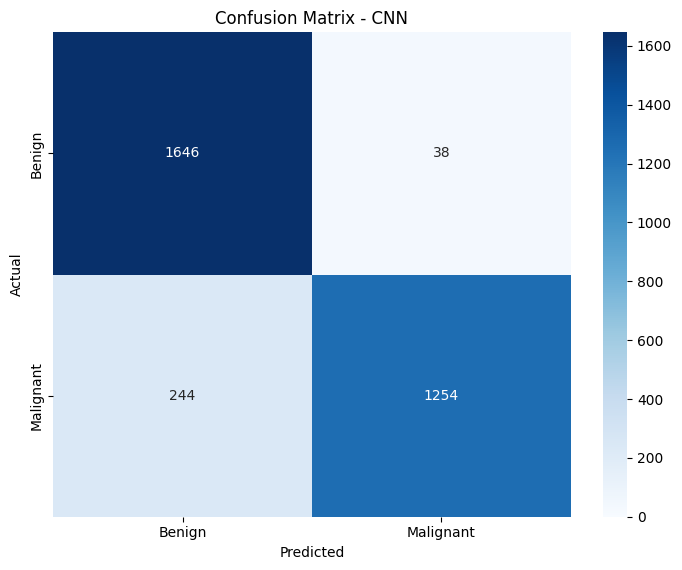

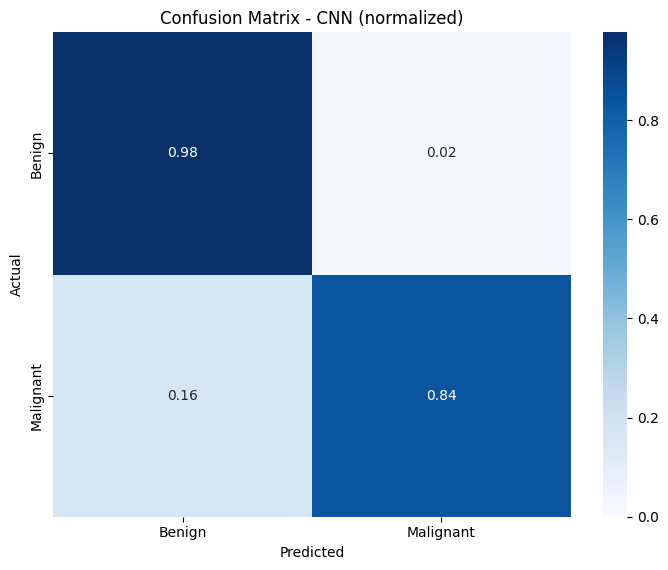

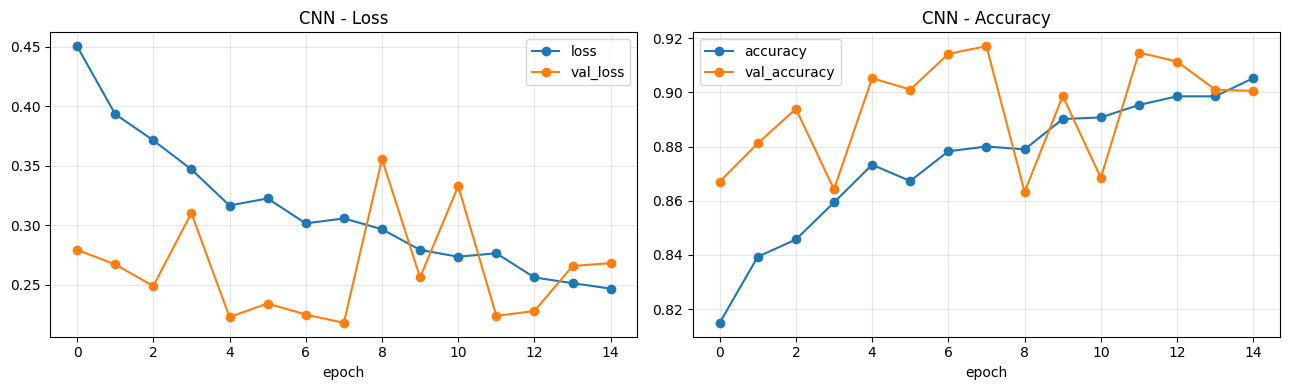


Saved results for [CNN] to /content/drive/MyDrive/Colab Notebooks/My Projects//Results/skin
accuracy=0.9114  f1_macro=0.9100  auc=0.9754


Saved: /content/drive/MyDrive/Colab Notebooks/My Projects//Results/skin/models/skin_CNN.keras


In [ ]:
# ---- Evaluation: CNN ----
print('Test set evaluation:')
model.evaluate(test, verbose=1)

test.reset()
y_prob = model.predict(test, verbose=1)
evaluate_and_log(MODEL_NAME, model, y_true_test, y_prob, history, train_time,
                 notes='from scratch')
save_model_files(MODEL_NAME, model)

del model
free_memory()

## Model 2: **MobileNet** - Train

In [ ]:
# ---- Train: MobileNet ----
MODEL_NAME = 'MobileNet'
free_memory()

base = MobileNet(input_shape=(IMG_SIZE, IMG_SIZE, 3), include_top=False, weights='imagenet')
base.trainable = False          # frozen backbone, same as the original script

model = models.Sequential([
    base,
    layers.GlobalAveragePooling2D(),
    layers.Dense(256, activation='relu'),
    layers.BatchNormalization(),
    layers.Dense(128, activation='relu'),
    layers.Dropout(0.3),
    layers.BatchNormalization(),
    layers.Dense(NUM_CLASSES, activation='softmax')
])

model.summary()

model.compile(loss='categorical_crossentropy',
              optimizer=tf.keras.optimizers.SGD(learning_rate=0.001),
              metrics=['accuracy'])

t0 = time.time()
history = model.fit(train, epochs=EPOCHS[MODEL_NAME], validation_data=val, verbose=1)
train_time = time.time() - t0
print(f'Training time: {train_time/60:.1f} minutes')

17225924/17225924 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ mobilenet_1.00_224 (Functional) │ (None, 8, 8, 1024)     │     3,228,864 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1024)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 256)            │       262,400 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 256)            │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 128)            │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 2)              │           258 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3,525,954 (13.45 MB)

 Trainable params: 296,322 (1.13 MB)

 Non-trainable params: 3,229,632 (12.32 MB)

Epoch 1/15
1061/1061 ━━━━━━━━━━━━━━━━━━━━ 77s 57ms/step - accuracy: 0.7915 - loss: 0.4713 - val_accuracy: 0.9029 - val_loss: 0.2694
Epoch 2/15
1061/1061 ━━━━━━━━━━━━━━━━━━━━ 36s 34ms/step - accuracy: 0.8487 - loss: 0.3764 - val_accuracy: 0.9147 - val_loss: 0.2401
Epoch 3/15
1061/1061 ━━━━━━━━━━━━━━━━━━━━ 34s 32ms/step - accuracy: 0.8567 - loss: 0.3580 - val_accuracy: 0.9184 - val_loss: 0.2330
Epoch 4/15
1061/1061 ━━━━━━━━━━━━━━━━━━━━ 35s 33ms/step - accuracy: 0.8627 - loss: 0.3376 - val_accuracy: 0.9213 - val_loss: 0.2235
Epoch 5/15
1061/1061 ━━━━━━━━━━━━━━━━━━━━ 39s 37ms/step - accuracy: 0.8794 - loss: 0.3065 - val_accuracy: 0.9217 - val_loss: 0.2213
Epoch 6/15
1061/1061 ━━━━━━━━━━━━━━━━━━━━ 36s 33ms/step - accuracy: 0.8715 - loss: 0.3074 - val_accuracy: 0.9222 - val_loss: 0.2184
Epoch 7/15
1061/1061 ━━━━━━━━━━━━━━━━━━━━ 35s 33ms/step - accuracy: 0.8797 - loss: 0.2979 - val_accuracy: 0.9217 - val_loss: 0.2178
Epoch 8/15
1061/1061 ━━━━━━━━━━━━━━━━━━━━ 35s 33ms/step - accuracy: 0.8818 -

### Model 2: **MobileNet** - Evaluation

Test set evaluation:
398/398 ━━━━━━━━━━━━━━━━━━━━ 22s 55ms/step - accuracy: 0.9280 - loss: 0.1942
398/398 ━━━━━━━━━━━━━━━━━━━━ 18s 36ms/step
              precision    recall  f1-score   support

      Benign       0.92      0.95      0.93      1684
   Malignant       0.94      0.90      0.92      1498

    accuracy                           0.93      3182
   macro avg       0.93      0.93      0.93      3182
weighted avg       0.93      0.93      0.93      3182



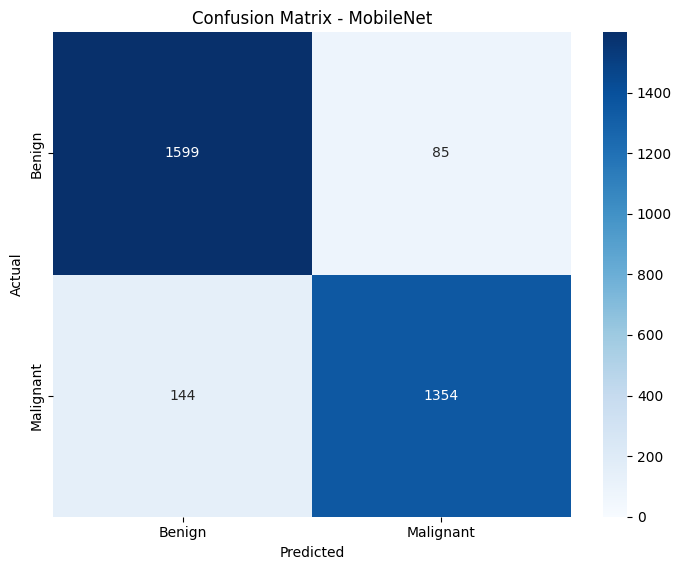

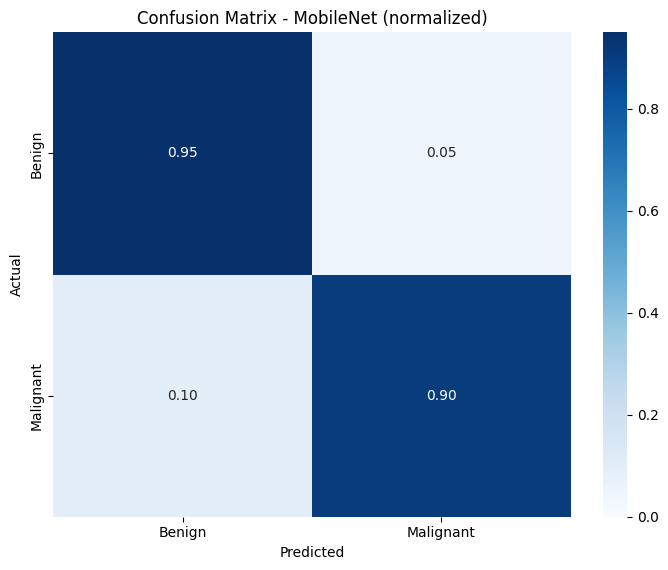

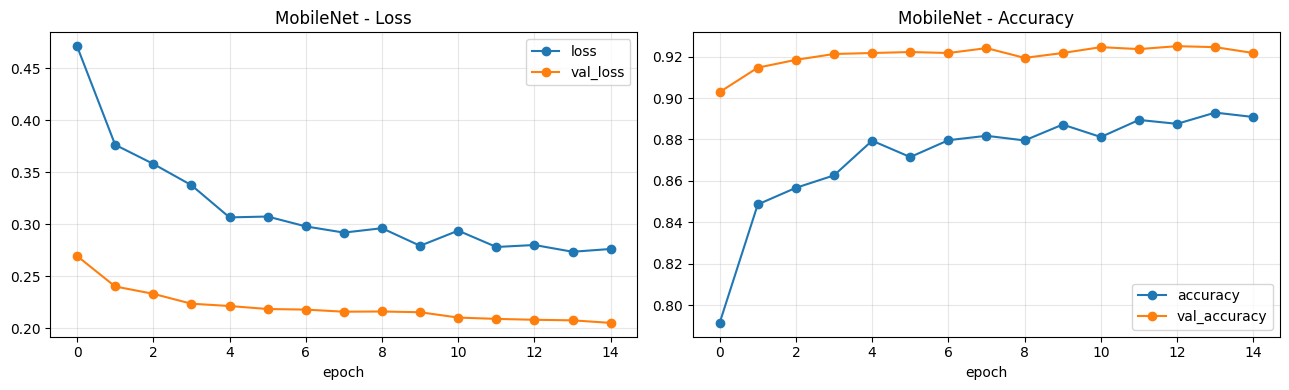


Saved results for [MobileNet] to /content/drive/MyDrive/Colab Notebooks/My Projects//Results/skin
accuracy=0.9280  f1_macro=0.9276  auc=0.9738


Saved: /content/drive/MyDrive/Colab Notebooks/My Projects//Results/skin/models/skin_MobileNet.keras


In [ ]:
# ---- Evaluation: MobileNet ----
print('Test set evaluation:')
model.evaluate(test, verbose=1)

test.reset()
y_prob = model.predict(test, verbose=1)
evaluate_and_log(MODEL_NAME, model, y_true_test, y_prob, history, train_time,
                 notes='frozen backbone')
save_model_files(MODEL_NAME, model)

del model
free_memory()

## Model 3: **VGG19** - Train

In [ ]:
# ---- Train: VGG19 ----
MODEL_NAME = 'VGG19'
free_memory()

base = VGG19(weights='imagenet', include_top=False, input_shape=(IMG_SIZE, IMG_SIZE, 3))
# Note: in the original script this backbone is NOT frozen, it is fully trainable

model = Sequential([
    base,
    Flatten(),
    Dense(512, activation='relu'),
    Dropout(0.3),
    Dense(256, activation='relu'),
    Dropout(0.3),
    Dense(128, activation='relu'),
    Dropout(0.3),
    Dense(NUM_CLASSES, activation='softmax')
])

model.summary()

model.compile(loss='categorical_crossentropy',
              optimizer=tf.keras.optimizers.SGD(learning_rate=0.001),
              metrics=['accuracy'])

t0 = time.time()
history = model.fit(train, epochs=EPOCHS[MODEL_NAME], validation_data=val, verbose=1)
train_time = time.time() - t0
print(f'Training time: {train_time/60:.1f} minutes')

80134624/80134624 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ vgg19 (Functional)              │ (None, 8, 8, 512)      │    20,024,384 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 32768)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 512)            │    16,777,728 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 512)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 256)            │       131,328 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 2)              │           258 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 36,966,594 (141.02 MB)

 Trainable params: 36,966,594 (141.02 MB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/15
1061/1061 ━━━━━━━━━━━━━━━━━━━━ 351s 303ms/step - accuracy: 0.8429 - loss: 0.3622 - val_accuracy: 0.8883 - val_loss: 0.2814
Epoch 2/15
1061/1061 ━━━━━━━━━━━━━━━━━━━━ 303s 286ms/step - accuracy: 0.9066 - loss: 0.2320 - val_accuracy: 0.9213 - val_loss: 0.1891
Epoch 3/15
1061/1061 ━━━━━━━━━━━━━━━━━━━━ 287s 270ms/step - accuracy: 0.9210 - loss: 0.2014 - val_accuracy: 0.9250 - val_loss: 0.1780
Epoch 4/15
1061/1061 ━━━━━━━━━━━━━━━━━━━━ 284s 268ms/step - accuracy: 0.9328 - loss: 0.1770 - val_accuracy: 0.9165 - val_loss: 0.2130
Epoch 5/15
1061/1061 ━━━━━━━━━━━━━━━━━━━━ 285s 268ms/step - accuracy: 0.9360 - loss: 0.1651 - val_accuracy: 0.9213 - val_loss: 0.1860
Epoch 6/15
1061/1061 ━━━━━━━━━━━━━━━━━━━━ 285s 268ms/step - accuracy: 0.9407 - loss: 0.1505 - val_accuracy: 0.9269 - val_loss: 0.1765
Epoch 7/15
1061/1061 ━━━━━━━━━━━━━━━━━━━━ 285s 268ms/step - accuracy: 0.9484 - loss: 0.1333 - val_accuracy: 0.9326 - val_loss: 0.1707
Epoch 8/15
1061/1061 ━━━━━━━━━━━━━━━━━━━━ 286s 270ms/step - ac

### Model 3: **VGG19** - Evaluation

Test set evaluation:
398/398 ━━━━━━━━━━━━━━━━━━━━ 43s 108ms/step - accuracy: 0.9488 - loss: 0.1826
398/398 ━━━━━━━━━━━━━━━━━━━━ 36s 89ms/step
              precision    recall  f1-score   support

      Benign       0.95      0.95      0.95      1684
   Malignant       0.94      0.95      0.95      1498

    accuracy                           0.95      3182
   macro avg       0.95      0.95      0.95      3182
weighted avg       0.95      0.95      0.95      3182



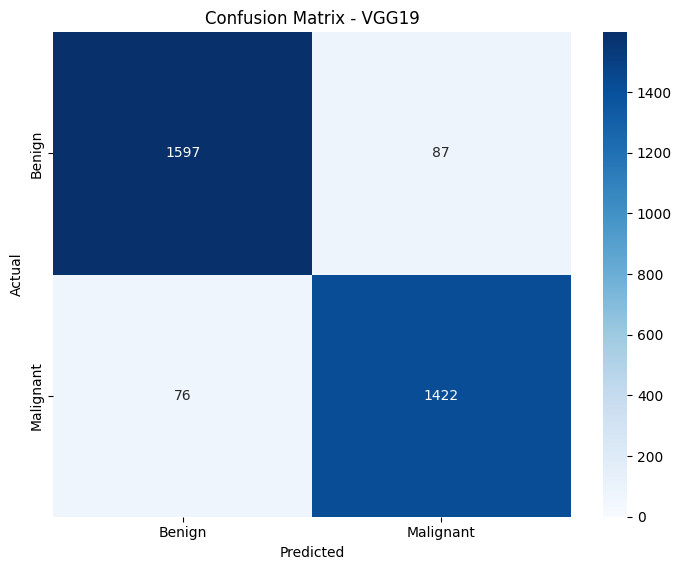

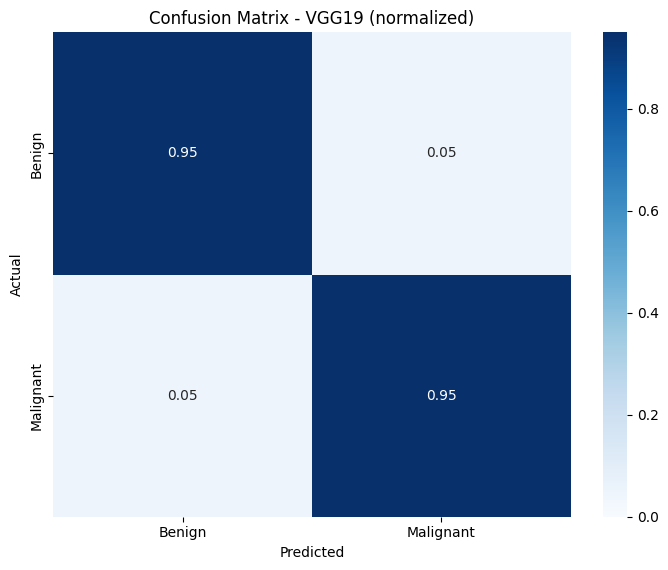

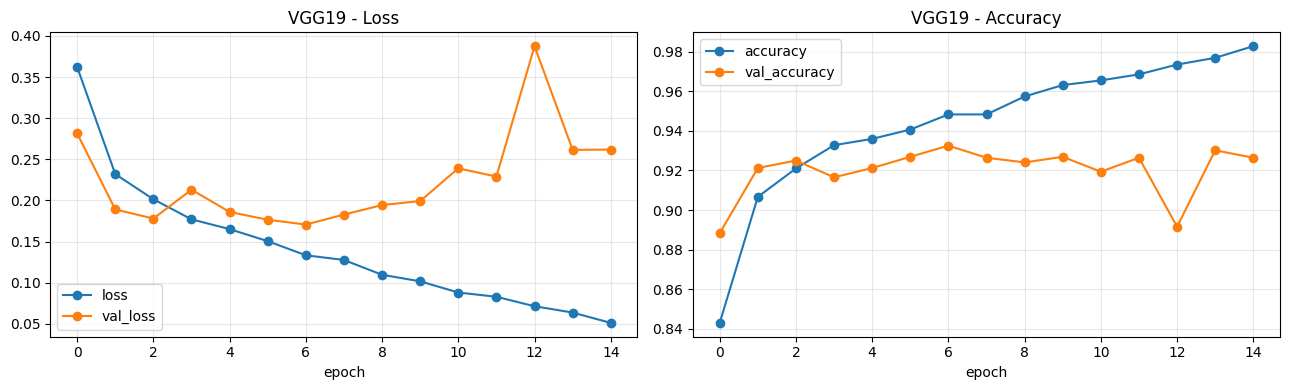


Saved results for [VGG19] to /content/drive/MyDrive/Colab Notebooks/My Projects//Results/skin
accuracy=0.9488  f1_macro=0.9486  auc=0.9880


Saved: /content/drive/MyDrive/Colab Notebooks/My Projects//Results/skin/models/skin_VGG19.keras


In [ ]:
# ---- Evaluation: VGG19 ----
print('Test set evaluation:')
model.evaluate(test, verbose=1)

test.reset()
y_prob = model.predict(test, verbose=1)
evaluate_and_log(MODEL_NAME, model, y_true_test, y_prob, history, train_time,
                 notes='trainable backbone')
save_model_files(MODEL_NAME, model)

del model
free_memory()

## Model 4: **ResNet50** - Train

In [ ]:
# ---- Train: ResNet50 ----
MODEL_NAME = 'ResNet50'
free_memory()

base = ResNet50(weights='imagenet', include_top=False, input_shape=(IMG_SIZE, IMG_SIZE, 3))
# Note: in the original script this backbone is NOT frozen, it is fully trainable

model = Sequential([
    base,
    Flatten(),
    Dense(512, activation='relu'),
    Dropout(0.3),
    Dense(256, activation='relu'),
    Dropout(0.3),
    Dense(128, activation='relu'),
    Dropout(0.3),
    Dense(NUM_CLASSES, activation='softmax')
])

model.summary()

model.compile(loss='categorical_crossentropy',
              optimizer=tf.keras.optimizers.SGD(learning_rate=0.001),
              metrics=['accuracy'])

t0 = time.time()
history = model.fit(train, epochs=EPOCHS[MODEL_NAME], validation_data=val, verbose=1)
train_time = time.time() - t0
print(f'Training time: {train_time/60:.1f} minutes')

94765736/94765736 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ resnet50 (Functional)           │ (None, 8, 8, 2048)     │    23,587,712 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 131072)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 512)            │    67,109,376 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 512)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 256)            │       131,328 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 2)              │           258 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 90,861,570 (346.61 MB)

 Trainable params: 90,808,450 (346.41 MB)

 Non-trainable params: 53,120 (207.50 KB)

Epoch 1/15
1061/1061 ━━━━━━━━━━━━━━━━━━━━ 195s 151ms/step - accuracy: 0.8571 - loss: 0.3644 - val_accuracy: 0.9203 - val_loss: 0.1968
Epoch 2/15
1061/1061 ━━━━━━━━━━━━━━━━━━━━ 131s 123ms/step - accuracy: 0.9165 - loss: 0.2140 - val_accuracy: 0.9302 - val_loss: 0.1743
Epoch 3/15
1061/1061 ━━━━━━━━━━━━━━━━━━━━ 131s 124ms/step - accuracy: 0.9364 - loss: 0.1682 - val_accuracy: 0.9345 - val_loss: 0.1676
Epoch 4/15
1061/1061 ━━━━━━━━━━━━━━━━━━━━ 132s 124ms/step - accuracy: 0.9432 - loss: 0.1424 - val_accuracy: 0.9331 - val_loss: 0.1701
Epoch 5/15
1061/1061 ━━━━━━━━━━━━━━━━━━━━ 132s 124ms/step - accuracy: 0.9564 - loss: 0.1180 - val_accuracy: 0.9331 - val_loss: 0.1763
Epoch 6/15
1061/1061 ━━━━━━━━━━━━━━━━━━━━ 130s 123ms/step - accuracy: 0.9669 - loss: 0.0889 - val_accuracy: 0.9298 - val_loss: 0.1916
Epoch 7/15
1061/1061 ━━━━━━━━━━━━━━━━━━━━ 132s 124ms/step - accuracy: 0.9717 - loss: 0.0758 - val_accuracy: 0.9118 - val_loss: 0.2371
Epoch 8/15
1061/1061 ━━━━━━━━━━━━━━━━━━━━ 131s 124ms/step - ac

### Model 4: **ResNet50** - Evaluation

Test set evaluation:
398/398 ━━━━━━━━━━━━━━━━━━━━ 17s 42ms/step - accuracy: 0.9519 - loss: 0.2067
398/398 ━━━━━━━━━━━━━━━━━━━━ 22s 45ms/step
              precision    recall  f1-score   support

      Benign       0.93      0.98      0.96      1684
   Malignant       0.97      0.92      0.95      1498

    accuracy                           0.95      3182
   macro avg       0.95      0.95      0.95      3182
weighted avg       0.95      0.95      0.95      3182



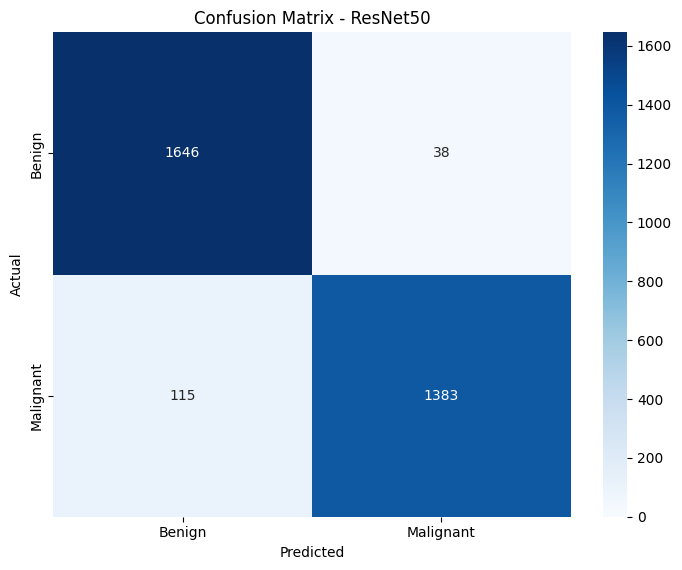

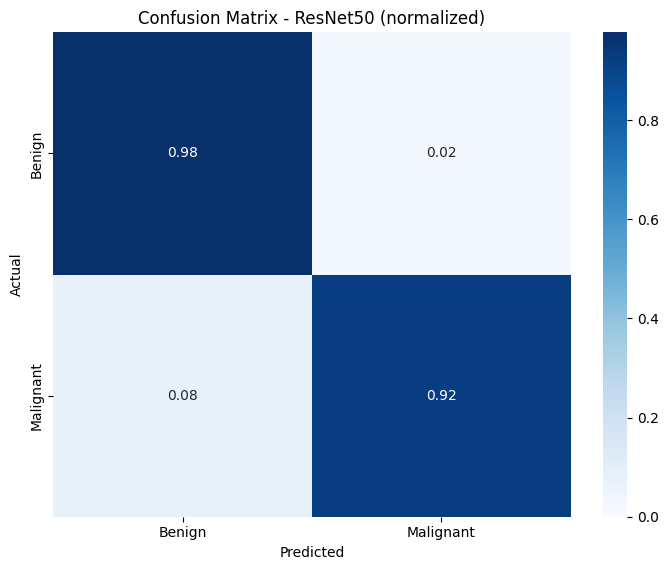

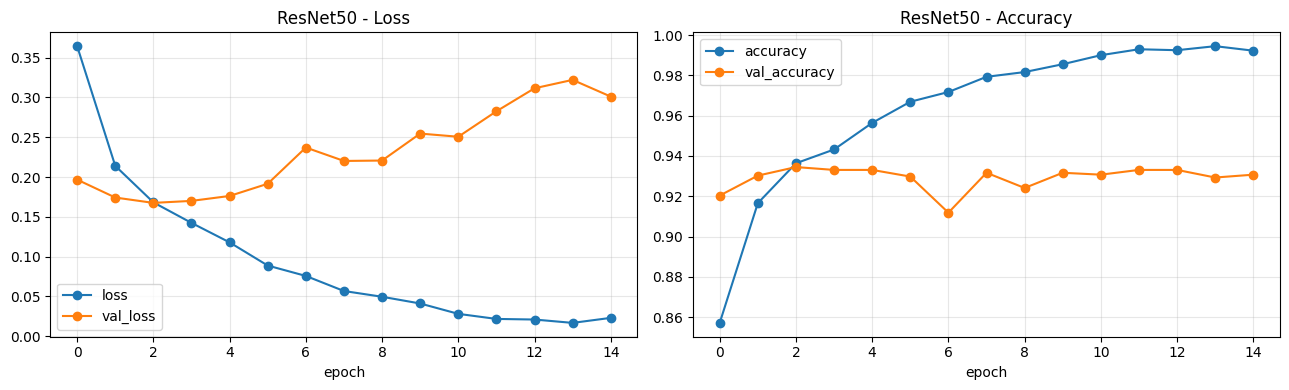


Saved results for [ResNet50] to /content/drive/MyDrive/Colab Notebooks/My Projects//Results/skin
accuracy=0.9519  f1_macro=0.9516  auc=0.9882


Saved: /content/drive/MyDrive/Colab Notebooks/My Projects//Results/skin/models/skin_ResNet50.keras


In [ ]:
# ---- Evaluation: ResNet50 ----
print('Test set evaluation:')
model.evaluate(test, verbose=1)

test.reset()
y_prob = model.predict(test, verbose=1)
evaluate_and_log(MODEL_NAME, model, y_true_test, y_prob, history, train_time,
                 notes='trainable backbone')
save_model_files(MODEL_NAME, model)

del model
free_memory()

## 8) Model Comparison

,model,accuracy,precision_macro,recall_macro,f1_macro,auc,train_time_sec,total_params
0,ResNet50,0.9519,0.9540,0.9503,0.9516,0.9882,2042.4,90861570
1,VGG19,0.9488,0.9485,0.9488,0.9486,0.9880,4364.6,36966594
2,MobileNet,0.9280,0.9292,0.9267,0.9276,0.9738,577.3,3525954
3,CNN,0.9114,0.9207,0.9073,0.9100,0.9754,1889.5,33684162


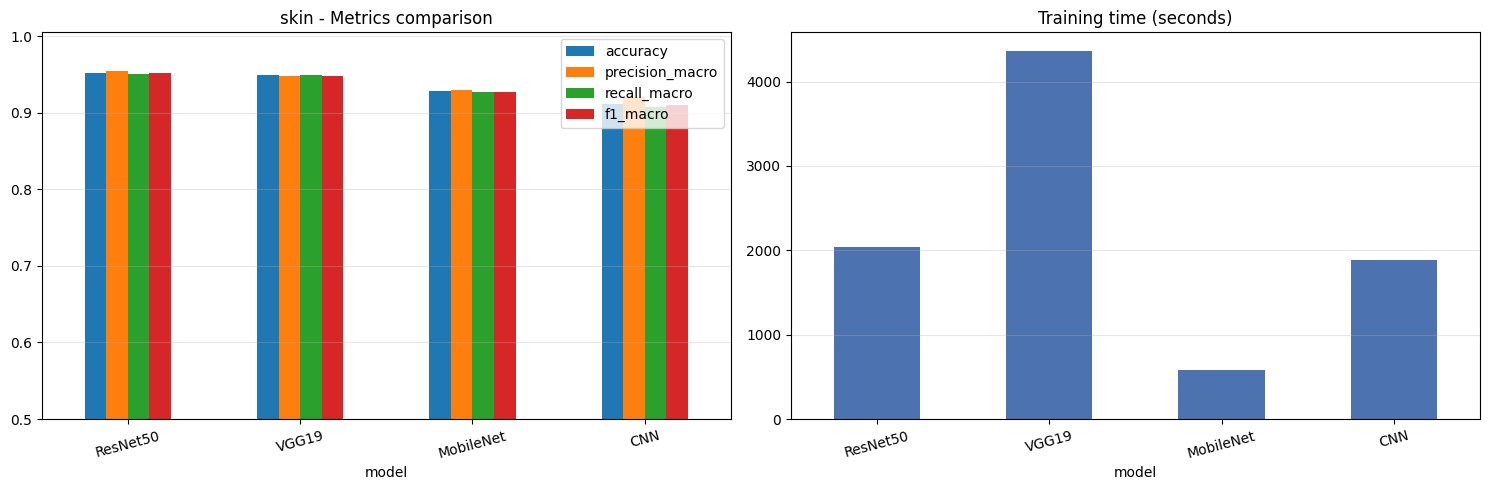

Best model by F1-macro: ResNet50 (accuracy=0.9519, f1=0.9516)


In [ ]:
# ============================================================
#  8) Model Comparison
# ============================================================
comp = pd.read_csv(COMPARISON_CSV)
display(comp[['model', 'accuracy', 'precision_macro', 'recall_macro', 'f1_macro',
              'auc', 'train_time_sec', 'total_params']])

m = comp.set_index('model')
fig, ax = plt.subplots(1, 2, figsize=(15, 5))
m[['accuracy', 'precision_macro', 'recall_macro', 'f1_macro']].plot.bar(ax=ax[0], rot=15)
ax[0].set_ylim(min(0.5, m['f1_macro'].min() - 0.05), 1.005)
ax[0].set_title(f'{CANCER_TYPE} - Metrics comparison'); ax[0].grid(axis='y', alpha=.3)
m[['train_time_sec']].plot.bar(ax=ax[1], rot=15, color='#4c72b0', legend=False)
ax[1].set_title('Training time (seconds)'); ax[1].grid(axis='y', alpha=.3)
plt.tight_layout()
plt.savefig(f'{RESULTS_DIR}/figures/model_comparison.png', dpi=120)
plt.show()

BEST_MODEL = comp.iloc[0]['model']
print(f'Best model by F1-macro: {BEST_MODEL} '
      f'(accuracy={comp.iloc[0]["accuracy"]:.4f}, f1={comp.iloc[0]["f1_macro"]:.4f})')


## 9) Final Evaluation

=== Final report: ResNet50 ===
              precision    recall  f1-score   support

      Benign       0.93      0.98      0.96      1684
   Malignant       0.97      0.92      0.95      1498

    accuracy                           0.95      3182
   macro avg       0.95      0.95      0.95      3182
weighted avg       0.95      0.95      0.95      3182



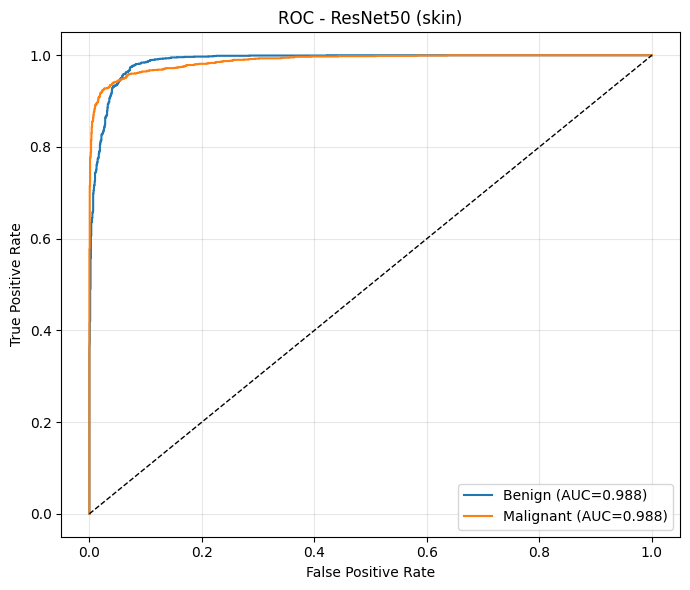

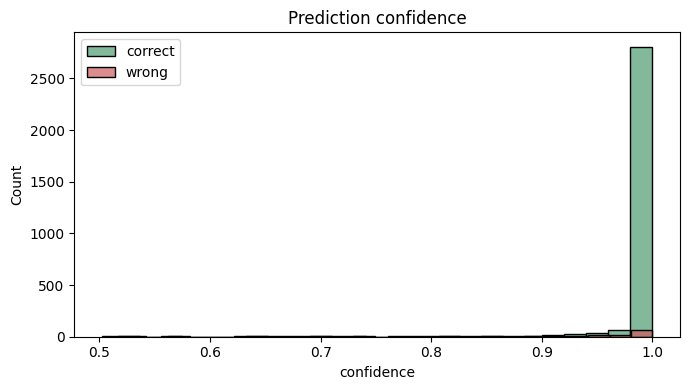

Errors: 153 out of 3182
Mean confidence on wrong predictions: 0.900


In [ ]:
# ============================================================
#  9) Final Evaluation - detailed report for the best model
# ============================================================
best_path = f'{RESULTS_DIR}/models/{CANCER_TYPE}_{BEST_MODEL}.keras'
best_model = tf.keras.models.load_model(best_path)

y_prob_best = np.load(f'{RESULTS_DIR}/predictions/{BEST_MODEL}_y_prob.npy')
y_true_best = np.load(f'{RESULTS_DIR}/predictions/{BEST_MODEL}_y_true.npy')
y_pred_best = y_prob_best.argmax(1)

print(f'=== Final report: {BEST_MODEL} ===')
print(metrics.classification_report(y_true_best, y_pred_best,
                                    labels=list(range(NUM_CLASSES)),
                                    target_names=CLASS_NAMES, zero_division=0))

# Per-class ROC curves
plt.figure(figsize=(7, 6))
for i, c in enumerate(CLASS_NAMES):
    fpr, tpr, _ = metrics.roc_curve((y_true_best == i).astype(int), y_prob_best[:, i])
    plt.plot(fpr, tpr, label=f'{c} (AUC={metrics.auc(fpr, tpr):.3f})')
plt.plot([0, 1], [0, 1], 'k--', lw=1)
plt.xlabel('False Positive Rate'); plt.ylabel('True Positive Rate')
plt.title(f'ROC - {BEST_MODEL} ({CANCER_TYPE})'); plt.legend(); plt.grid(alpha=.3)
plt.tight_layout(); plt.savefig(f'{RESULTS_DIR}/figures/final_roc.png', dpi=120); plt.show()

# Confidence distribution: correct vs wrong predictions
conf = y_prob_best.max(1)
correct = y_pred_best == y_true_best
plt.figure(figsize=(7, 4))
sns.histplot(conf[correct], bins=25, label='correct', color='seagreen', alpha=.6)
sns.histplot(conf[~correct], bins=25, label='wrong', color='indianred', alpha=.7)
plt.xlabel('confidence'); plt.legend(); plt.title('Prediction confidence')
plt.tight_layout(); plt.savefig(f'{RESULTS_DIR}/figures/final_confidence.png', dpi=120); plt.show()

print(f'Errors: {int((~correct).sum())} out of {len(correct)}')
if (~correct).any():
    print('Mean confidence on wrong predictions: %.3f' % conf[~correct].mean())


## 10) Explainability - Grad-CAM

Red regions are the areas the model relied on. If the model focuses on the background or the image borders instead of the tissue, the problem is in the data rather than in the architecture.

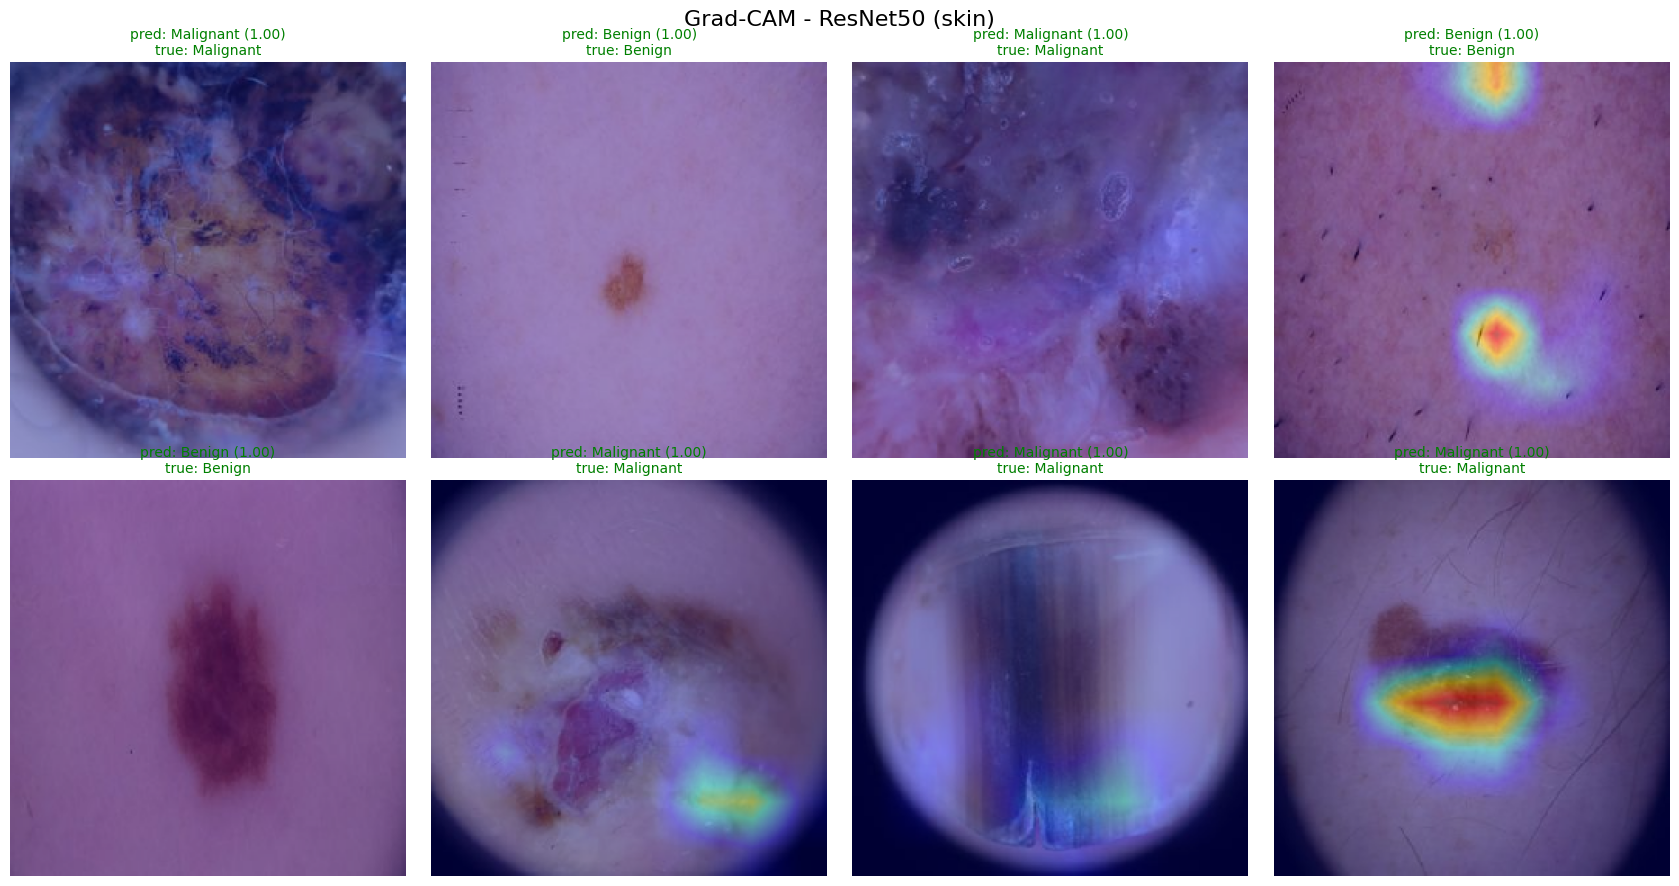

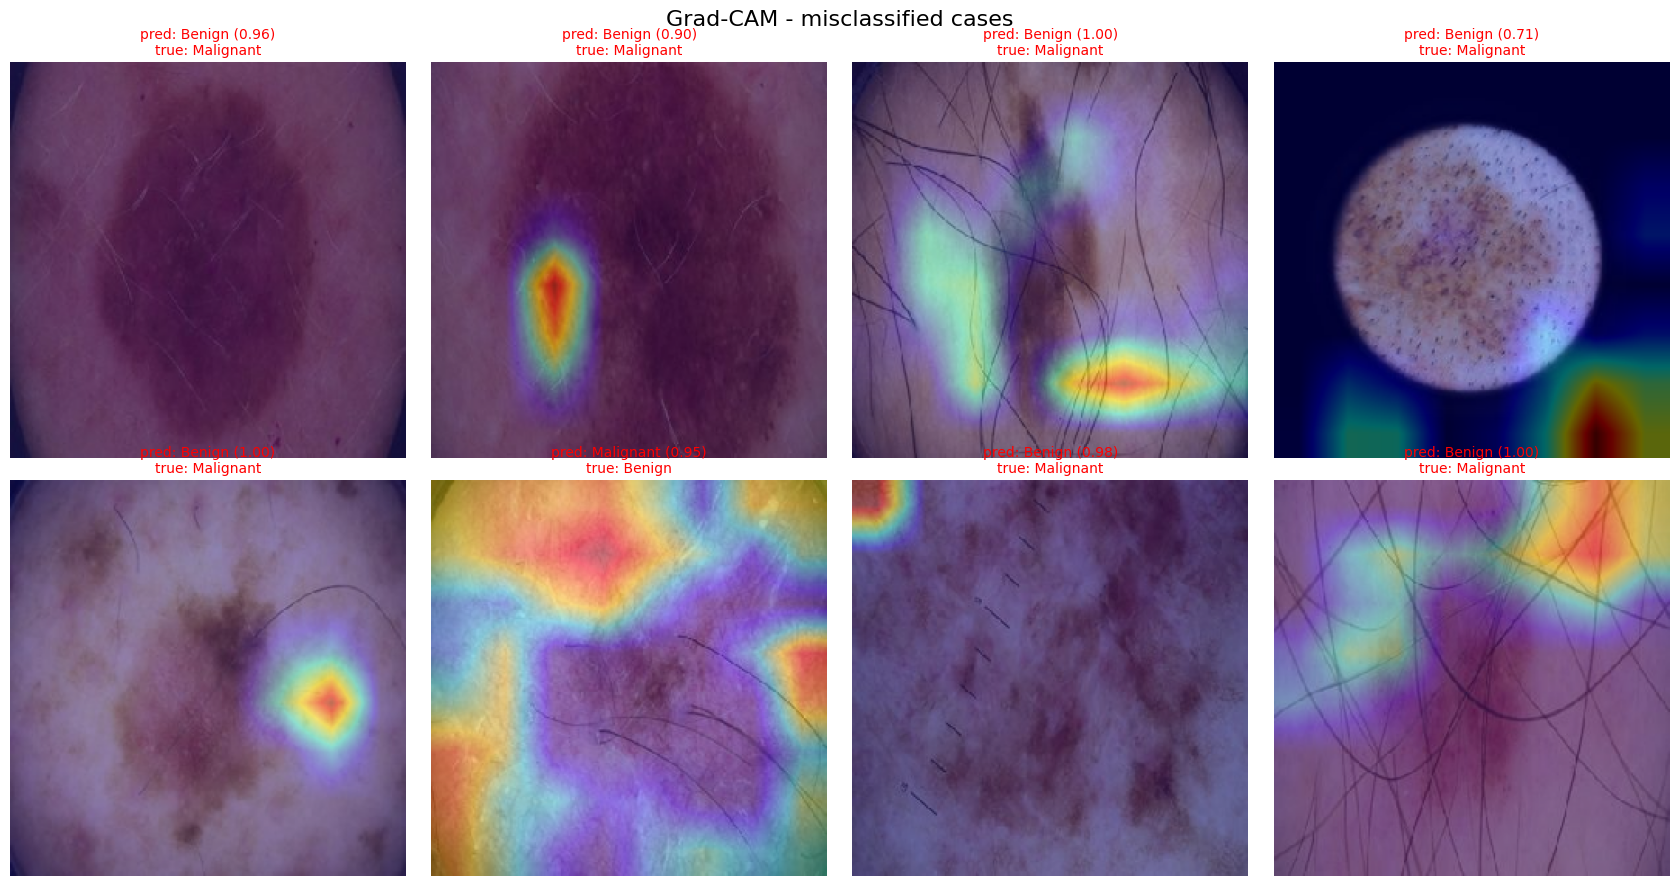

In [ ]:
# ============================================================
#  10) Explainability - Grad-CAM on the best model
# ============================================================
test_paths = np.array(test.filepaths)
rng = np.random.RandomState(SEED)
idxs = rng.choice(len(test_paths), 8, replace=False)

def _load_pair(path):
    img = load_img(path, target_size=(IMG_SIZE, IMG_SIZE))
    disp = np.array(img)
    inp = np.expand_dims(
        tf.keras.applications.mobilenet_v2.preprocess_input(img_to_array(img)), 0)
    return disp, inp

fig, axes = plt.subplots(2, 4, figsize=(17, 9))
fig.suptitle(f'Grad-CAM - {BEST_MODEL} ({CANCER_TYPE})', fontsize=16)
for ax, i in zip(axes.ravel(), idxs):
    disp, inp = _load_pair(test_paths[i])
    show_gradcam(best_model, disp, inp, CLASS_NAMES[y_true_best[i]], ax=ax)
plt.tight_layout()
plt.savefig(f'{RESULTS_DIR}/figures/gradcam_samples.png', dpi=120)
plt.show()

wrong = np.where(y_pred_best != y_true_best)[0]
if len(wrong):
    sel = wrong[:8]
    fig, axes = plt.subplots(2, 4, figsize=(17, 9))
    fig.suptitle('Grad-CAM - misclassified cases', fontsize=16)
    for ax, i in zip(axes.ravel(), sel):
        disp, inp = _load_pair(test_paths[i])
        show_gradcam(best_model, disp, inp, CLASS_NAMES[y_true_best[i]], ax=ax)
    for ax in axes.ravel()[len(sel):]:
        ax.axis('off')
    plt.tight_layout()
    plt.savefig(f'{RESULTS_DIR}/figures/gradcam_errors.png', dpi=120)
    plt.show()
else:
    print('No misclassified samples')

## 11) Save Model

In [ ]:
# ============================================================
#  11) Save Model and export a deployment bundle
# ============================================================
DEPLOY_DIR = f'{PROJECT_DIR}/Deploy/{CANCER_TYPE}'
os.makedirs(DEPLOY_DIR, exist_ok=True)

import shutil
shutil.copy(f'{RESULTS_DIR}/models/{CANCER_TYPE}_{BEST_MODEL}.keras',
            f'{DEPLOY_DIR}/{CANCER_TYPE}_best.keras')
shutil.copy(f'{RESULTS_DIR}/models/{CANCER_TYPE}_{BEST_MODEL}.h5',
            f'{DEPLOY_DIR}/{CANCER_TYPE}_best.h5')

meta = {
    'cancer_type': CANCER_TYPE,
    'architecture': BEST_MODEL,
    'class_names': CLASS_NAMES,          # exact order of the softmax outputs
    'img_size': IMG_SIZE,
    'preprocessing': PREPROCESS_NAME,    # must match the preprocessing used during training
    'metrics': comp.iloc[0].to_dict(),
    'saved_at': time.strftime('%Y-%m-%d %H:%M:%S'),
}
with open(f'{DEPLOY_DIR}/model_meta.json', 'w') as fh:
    json.dump(meta, fh, indent=2, default=str)

print('Deployment bundle saved to:', DEPLOY_DIR)
for f in sorted(os.listdir(DEPLOY_DIR)):
    print(' -', f)
print('\nAll results:', RESULTS_DIR)
print(' - comparison.csv / all_results.json / summary.xlsx')


Deployment bundle saved to: /content/drive/MyDrive/Colab Notebooks/My Projects//Deploy/skin
 - model_meta.json
 - skin_best.h5
 - skin_best.keras

All results: /content/drive/MyDrive/Colab Notebooks/My Projects//Results/skin
 - comparison.csv / all_results.json / summary.xlsx


In [ ]:
# ============================================================
#  Quick check: predict a single image using the training preprocessing.
#  This is the exact same logic used by the Flask API.
# ============================================================
def predict_image(image_path, model=None, meta_path=f'{DEPLOY_DIR}/model_meta.json'):
    with open(meta_path) as fh:
        meta = json.load(fh)
    model = model or tf.keras.models.load_model(
        f'{DEPLOY_DIR}/{meta["cancer_type"]}_best.keras')
    size = meta['img_size']

    if meta['preprocessing'] == 'bgr_raw':
        # Colon / Lung training: cv2.imread (BGR) + resize, no normalization
        arr = cv2.resize(cv2.imread(image_path), (size, size)).astype('float32')
    else:
        # Leukemia / Skin training: RGB + mobilenet_v2.preprocess_input
        img = load_img(image_path, target_size=(size, size))
        arr = tf.keras.applications.mobilenet_v2.preprocess_input(img_to_array(img))

    arr = np.expand_dims(arr, 0)
    probs = model.predict(arr, verbose=0)[0]
    idx = int(np.argmax(probs))
    return {'label': meta['class_names'][idx],
            'confidence': float(probs[idx]),
            'all_probs': dict(zip(meta['class_names'], probs.round(4).tolist()))}

sample_path = df['filepath'].iloc[0]
print('Image:', os.path.basename(sample_path), '| Ground truth:', df['label'].iloc[0])
predict_image(sample_path)


Image: melanoma_473.jpg | Ground truth: Benign


{'label': 'Benign',
 'confidence': 0.9999994039535522,
 'all_probs': {'Benign': 1.0, 'Malignant': 0.0}}

---
### Done

Everything is stored under `Results/skin/` and `Deploy/skin/` on Google Drive.

These models are for research and academic use only, not a medical diagnostic tool.